In [7]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os
from pptx import Presentation
from pptx.util import Inches
import openpyxl
import matplotlib as mpl
import streamlit as st

In [8]:
archivo = '../data/videojuegos.csv'
df = pd.read_csv(archivo)
df.head()

,Game,Platform,Manufacturer,Year,Genre,Publisher,North America,Europe,Japan,Rest of World,Global
0,Grand Theft Auto V,PS4,Sony,2014.0,Action,Rockstar Games,6.06,9.71,0.60,3.02,19.39
1,Call of Duty: Black Ops 3,PS4,Sony,2015.0,Shooter,Activision,6.18,6.05,0.41,2.44,15.09
2,Red Dead Redemption 2,PS4,Sony,2018.0,Action-Adventure,Rockstar Games,5.26,6.21,0.21,2.26,13.94
3,Call of Duty: WWII,PS4,Sony,2017.0,Shooter,Activision,4.67,6.21,0.40,2.12,13.40
4,FIFA 18,PS4,Sony,2017.0,Sports,EA Sports,1.27,8.64,0.15,1.73,11.80


In [9]:
df['Year'] = df['Year'].astype('Int64')

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 23178 entries, 0 to 23177
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Game           23178 non-null  str    
 1   Platform       23178 non-null  str    
 2   Manufacturer   23178 non-null  str    
 3   Year           22519 non-null  Int64  
 4   Genre          23178 non-null  str    
 5   Publisher      22802 non-null  str    
 6   North America  23178 non-null  float64
 7   Europe         23178 non-null  float64
 8   Japan          23178 non-null  float64
 9   Rest of World  23178 non-null  float64
 10  Global         23178 non-null  float64
dtypes: Int64(1), float64(5), str(5)
memory usage: 3.1 MB


In [11]:
porcentaje_nulos = (df.isnull().sum() / len(df)) * 100
porcentaje_nulos

Game             0.000000
Platform         0.000000
Manufacturer     0.000000
Year             2.843213
Genre            0.000000
Publisher        1.622228
North America    0.000000
Europe           0.000000
Japan            0.000000
Rest of World    0.000000
Global           0.000000
dtype: float64

El porcentaje de nulos tanto en la columna Year como en la de Publisher es muy pequeño por lo que no hace falta eliminar esos datos. ¿Podríamos inputar esos datos de alguna forma?

In [12]:
df['Game'].nunique()

12263

Podemos ver que hay videojuegos repetidos, es decir, un mismo videojuego se vende para una misma plataforma. Así que, un primer método sería imputar a un videojuego el año que salió en otra plataforma.

In [13]:
df['Year'] = df['Year'].fillna(df.groupby('Game')['Year'].transform('first'))
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 23178 entries, 0 to 23177
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Game           23178 non-null  str    
 1   Platform       23178 non-null  str    
 2   Manufacturer   23178 non-null  str    
 3   Year           22711 non-null  Int64  
 4   Genre          23178 non-null  str    
 5   Publisher      22802 non-null  str    
 6   North America  23178 non-null  float64
 7   Europe         23178 non-null  float64
 8   Japan          23178 non-null  float64
 9   Rest of World  23178 non-null  float64
 10  Global         23178 non-null  float64
dtypes: Int64(1), float64(5), str(5)
memory usage: 3.1 MB


Hemos conseguido imputar algunos datos, pero todavía quedan 467 datos missing. Vamos a hacer lo mismo con Publisher.

In [12]:
clave = df['Game'].str.strip().str.lower() # no queremos que tenga en cuenta mayúsculas o minúsculas

df['Publisher'] = df['Publisher'].fillna(df.groupby(clave)['Publisher'].transform('first'))
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 23178 entries, 0 to 23177
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Game           23178 non-null  str    
 1   Platform       23178 non-null  str    
 2   Manufacturer   23178 non-null  str    
 3   Year           22711 non-null  Int64  
 4   Genre          23178 non-null  str    
 5   Publisher      22838 non-null  str    
 6   North America  23178 non-null  float64
 7   Europe         23178 non-null  float64
 8   Japan          23178 non-null  float64
 9   Rest of World  23178 non-null  float64
 10  Global         23178 non-null  float64
dtypes: Int64(1), float64(5), str(5)
memory usage: 3.1 MB


Hemos conseguido imputar algunos datos, pero todavía quedan 340 datos missing.

In [14]:
df.describe()

,Year,North America,Europe,Japan,Rest of World,Global
count,22711.0,23178.000000,23178.000000,23178.000000,23178.000000,23178.000000
mean,2007.884814,0.292838,0.179921,0.072677,0.059235,0.604891
std,5.808505,0.868053,0.596062,0.307926,0.203402,1.723504
min,1980.0,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2005.0,0.010000,0.000000,0.000000,0.000000,0.060000
50%,2009.0,0.090000,0.030000,0.000000,0.010000,0.190000
75%,2012.0,0.270000,0.140000,0.030000,0.050000,0.540000
max,2020.0,41.490000,29.020000,10.220000,10.570000,82.740000


## Análisis de las ventas de videojuegos univariante

| Variable  | Tipo  |
| ---   | ---   |
| Game  | Categórica    |
| Platform   | Categórica    |
| Manufacturer   | Categórica |
| Year  | Numérica Continua |
| Genre | Categórica    |
| Publisher  | Categórica    |
| North America | Numérica Continua    |
| Europe    | Numérica Continua |
| Japan | Numérica Continua |
| Rest of World | Numérica Continua |
| Global    | Numérica Continua |

In [ ]:
# Análisis de Videojuegos

df['Game'].describe()

count       23178
unique      12263
top       FIFA 15
freq           18
Name: Game, dtype: object

In [21]:
frec_game = df['Game'].value_counts()
frecr_game = df['Game'].value_counts(normalize=True) * 100
frecs_game = pd.DataFrame({'Frecuencia Absoluta': frec_game, 'Frecuencia Relativa': frecr_game})
print(frecs_game)

                              Frecuencia Absoluta  Frecuencia Relativa
Game                                                                  
FIFA 15                                        18             0.077660
FIFA 14                                        18             0.077660
Need for Speed: Most Wanted                    18             0.077660
LEGO Jurassic World                            17             0.073345
Lego Batman 3: Beyond Gotham                   17             0.073345
...                                           ...                  ...
Funk of Titans                                  1             0.004314
Fruit Ninja Kinect 2                            1             0.004314
Blues and Bullets                               1             0.004314
Gigantic                                        1             0.004314
Kaiju Panic                                     1             0.004314

[12263 rows x 2 columns]


In [23]:
# Análisis de Consolas
df['Platform'].describe()

count     23178
unique       31
top          DS
freq       3031
Name: Platform, dtype: object

In [24]:
frec_platform = df['Platform'].value_counts()
frecr_platform = df['Platform'].value_counts(normalize=True) * 100
frecs_platform = pd.DataFrame({'Frecuencia Absoluta': frec_platform, 'Frecuencia Relativa': frecr_platform})
print(frecs_platform)

          Frecuencia Absoluta  Frecuencia Relativa
Platform                                          
DS                       3031            13.077056
PS3                      2223             9.590991
Wii                      2180             9.405471
PS2                      2162             9.327811
X360                     1938             8.361377
PS4                      1658             7.153335
PSP                      1488             6.419881
PC                       1328             5.729571
PS                       1197             5.164380
Xbox One                 1027             4.430926
XB                        824             3.555095
GBA                       822             3.546466
3DS                       692             2.985590
PSV                       625             2.696523
GC                        556             2.398826
N64                       319             1.376305
WiiU                      257             1.108810
SNES                      239  

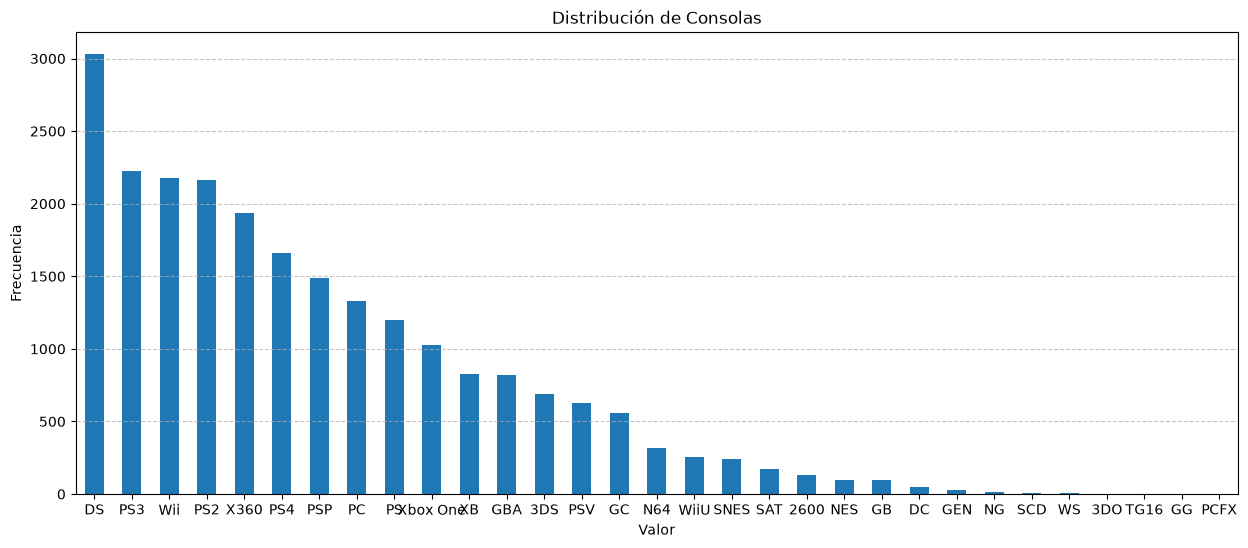

In [29]:
plt.figure(figsize=(15, 6))
frec_platform.plot(kind='bar')
plt.title('Distribución de Consolas')
plt.xlabel('Valor')
plt.ylabel('Frecuencia')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [30]:
# Análisis de Fabricante
df['Manufacturer'].describe()

count     23178
unique       10
top        Sony
freq       9353
Name: Manufacturer, dtype: object

In [31]:
frec_fabricante = df['Manufacturer'].value_counts()
frecr_fabricante = df['Manufacturer'].value_counts(normalize=True) * 100
frecs_fabricante = pd.DataFrame({'Frecuencia Absoluta': frec_fabricante, 'Frecuencia Relativa': frecr_fabricante})
print(frecs_fabricante)

                 Frecuencia Absoluta  Frecuencia Relativa
Manufacturer                                             
Sony                            9353            40.352921
Nintendo                        8292            35.775304
Microsoft                       3789            16.347398
PC                              1328             5.729571
Sega                             259             1.117439
Atari                            133             0.573820
SNK                               12             0.051773
Bandai                             6             0.025887
NEC                                3             0.012943
The 3DO Company                    3             0.012943


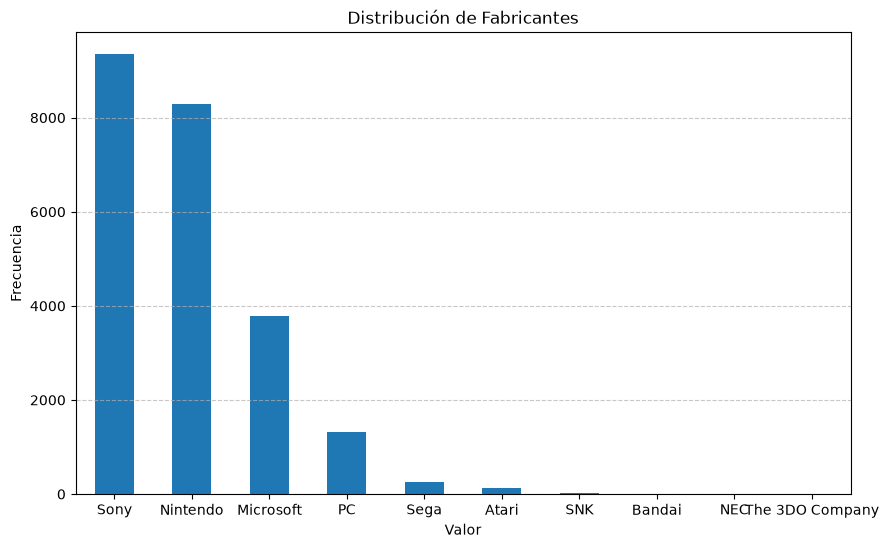

In [36]:
plt.figure(figsize=(10, 6))
frec_fabricante.plot(kind='bar')
plt.title('Distribución de Fabricantes')
plt.xlabel('Valor')
plt.ylabel('Frecuencia')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [34]:
# Análisis géneros
df['Genre'].describe()

count      23178
unique        17
top       Action
freq        5021
Name: Genre, dtype: object

In [35]:
frec_genre = df['Genre'].value_counts()
frecr_genre = df['Genre'].value_counts(normalize=True) * 100
frecs_genre = pd.DataFrame({'Frecuencia Absoluta': frec_genre, 'Frecuencia Relativa': frecr_genre})
print(frecs_genre)

                  Frecuencia Absoluta  Frecuencia Relativa
Genre                                                     
Action                           5021            21.662784
Sports                           3044            13.133143
Misc                             2487            10.730003
Role-Playing                     2097             9.047373
Shooter                          1927             8.313918
Adventure                        1709             7.373371
Racing                           1665             7.183536
Simulation                       1197             5.164380
Platform                         1167             5.034947
Fighting                         1098             4.737251
Strategy                          881             3.801018
Puzzle                            759             3.274657
Action-Adventure                   71             0.306325
Music                              33             0.142376
MMO                                10             0.0431

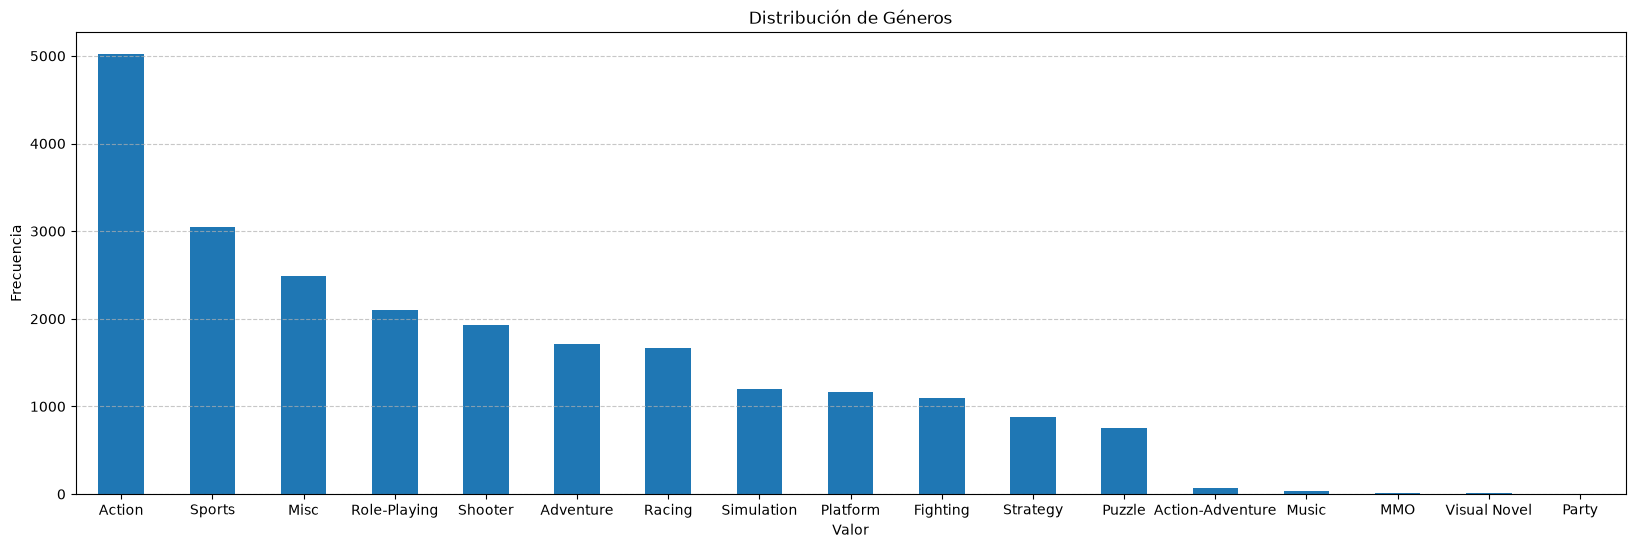

In [37]:
plt.figure(figsize=(20, 6))
frec_genre.plot(kind='bar')
plt.title('Distribución de Géneros')
plt.xlabel('Valor')
plt.ylabel('Frecuencia')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [38]:
# Análisis Publisher
df['Publisher'].describe()

count               22838
unique                655
top       Electronic Arts
freq                 1903
Name: Publisher, dtype: object

In [39]:
frec_publisher = df['Publisher'].value_counts()
frecr_publisher = df['Publisher'].value_counts(normalize=True) * 100
frecs_publisher = pd.DataFrame({'Frecuencia Absoluta': frec_publisher, 'Frecuencia Relativa': frecr_publisher})
print(frecs_publisher)

                              Frecuencia Absoluta  Frecuencia Relativa
Publisher                                                             
Electronic Arts                              1903             8.332604
Activision                                   1468             6.427883
Ubisoft                                      1450             6.349067
Namco Bandai Games                           1202             5.263158
Konami Digital Entertainment                  992             4.343638
...                                           ...                  ...
11 bit studios                                  1             0.004379
Wizards of the Coast                            1             0.004379
PlatinumGames                                   1             0.004379
Triangle Service                                1             0.004379
Snail Game                                      1             0.004379

[655 rows x 2 columns]


In [40]:
# Análisis de Year
df['Year'].describe()

count        22711.0
mean     2007.884814
std         5.808505
min           1980.0
25%           2005.0
50%           2009.0
75%           2012.0
max           2020.0
Name: Year, dtype: Float64

In [ ]:
# Tendencia central
media_year = df['Year'].mean().round(2)
mediana_year = df['Year'].median()
moda_year = df['Year'].mode()

# Medidas de dispersion
min_year = df['Year'].min()
max_year = df['Year'].max()
rango_year = max_year - min_year
var_year = df['Year'].var()
desv_year = df['Year'].std()
coef_year = desv_year / media_year

analisis_year = pd.DataFrame({'Media':media_year, 'Mediana':mediana_year, 'Moda':moda_year, 'Mínimo':min_year, 'Máximo':max_year, 'Rango':rango_year, 'Varianza': var_year, 'Desviación Típica': desv_year, 'Coeficiente Variacion':coef_year})
analisis_year

,Media,Mediana,Moda,Mínimo,Máximo,Rango,Varianza,Desviación Típica,Coeficiente Variacion
0,2007.88,2009.0,2009,1980,2020,40,33.738735,5.808505,0.002893


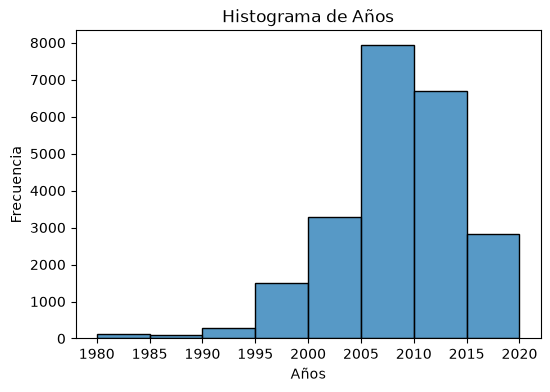

In [42]:
plt.figure(figsize=(6,4))
sns.histplot(df['Year'], bins=8, kde=False)
plt.title('Histograma de Años')
plt.xlabel('Años')
plt.ylabel('Frecuencia')
plt.show()

In [43]:
# Análisis de Global
df['Global'].describe()

count    23178.000000
mean         0.604891
std          1.723504
min          0.000000
25%          0.060000
50%          0.190000
75%          0.540000
max         82.740000
Name: Global, dtype: float64

In [44]:
# Tendencia central
media_global = df['Global'].mean().round(2)
mediana_global = df['Global'].median()
moda_global = df['Global'].mode()

# Medidas de dispersion
min_global = df['Global'].min()
max_global = df['Global'].max()
rango_global = max_global - min_global
var_global = df['Global'].var()
desv_global = df['Global'].std()
coef_global = desv_global / media_global

analisis_global = pd.DataFrame({'Media':media_global, 'Mediana':mediana_global, 'Moda':moda_global, 'Mínimo':min_global, 'Máximo':max_global, 'Rango':rango_global, 'Varianza': var_global, 'Desviación Típica': desv_global, 'Coeficiente Variacion':coef_global})
analisis_global

,Media,Mediana,Moda,Mínimo,Máximo,Rango,Varianza,Desviación Típica,Coeficiente Variacion
0,0.6,0.19,0.02,0.0,82.74,82.74,2.970466,1.723504,2.872507


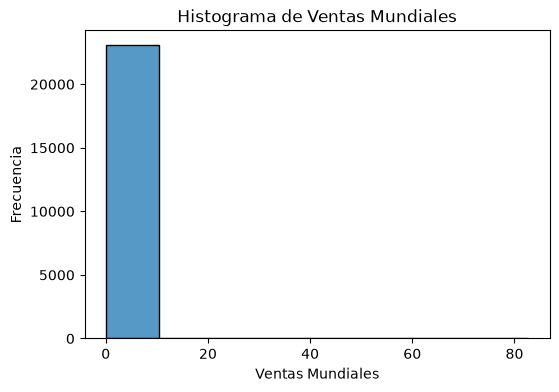

In [45]:
plt.figure(figsize=(6,4))
sns.histplot(df['Global'], bins=8, kde=False)
plt.title('Histograma de Ventas Mundiales')
plt.xlabel('Ventas Mundiales')
plt.ylabel('Frecuencia')
plt.show()

In [ ]:
# Análisis de Norte América
df['North America'].describe()

count    23178.000000
mean         0.292838
std          0.868053
min          0.000000
25%          0.010000
50%          0.090000
75%          0.270000
max         41.490000
Name: North America, dtype: float64

In [17]:
# Tendencia central
media_na = df['North America'].mean().round(2)
mediana_na = df['North America'].median()
moda_na = df['North America'].mode()

# Medidas de dispersion
min_na = df['North America'].min()
max_na = df['North America'].max()
rango_na = max_na - min_na
var_na = df['North America'].var()
desv_na = df['North America'].std()
coef_na = desv_na / media_na

analisis_na = pd.DataFrame({'Media':media_na, 'Mediana':mediana_na, 'Moda':moda_na, 'Mínimo':min_na, 'Máximo':max_na, 'Rango':rango_na, 'Varianza': var_na, 'Desviación Típica': desv_na, 'Coeficiente Variacion':coef_na})
analisis_na

,Media,Mediana,Moda,Mínimo,Máximo,Rango,Varianza,Desviación Típica,Coeficiente Variacion
0,0.29,0.09,0.0,0.0,41.49,41.49,0.753516,0.868053,2.993287


In [20]:
# Análisis de Europa
df['Europe'].describe()

count    23178.000000
mean         0.179921
std          0.596062
min          0.000000
25%          0.000000
50%          0.030000
75%          0.140000
max         29.020000
Name: Europe, dtype: float64

In [19]:
# Tendencia central
media_eu = df['Europe'].mean().round(2)
mediana_eu = df['Europe'].median()
moda_eu = df['Europe'].mode()

# Medidas de dispersion
min_eu = df['Europe'].min()
max_eu = df['Europe'].max()
rango_eu = max_eu - min_eu
var_eu = df['Europe'].var()
desv_eu = df['Europe'].std()
coef_eu = desv_eu / media_eu

analisis_eu = pd.DataFrame({'Media':media_eu, 'Mediana':mediana_eu, 'Moda':moda_eu, 'Mínimo':min_eu, 'Máximo':max_eu, 'Rango':rango_eu, 'Varianza': var_eu, 'Desviación Típica': desv_eu, 'Coeficiente Variacion':coef_eu})
analisis_eu

,Media,Mediana,Moda,Mínimo,Máximo,Rango,Varianza,Desviación Típica,Coeficiente Variacion
0,0.18,0.03,0.0,0.0,29.02,29.02,0.35529,0.596062,3.311456


In [21]:
# Análisis de Japón
df['Japan'].describe()

count    23178.000000
mean         0.072677
std          0.307926
min          0.000000
25%          0.000000
50%          0.000000
75%          0.030000
max         10.220000
Name: Japan, dtype: float64

In [ ]:
# Tendencia central
media_jp = df['Japan'].mean().round(2)
mediana_jp = df['Japan'].median()
moda_jp = df['Japan'].mode()

# Medidas de dispersion
min_jp = df['Japan'].min()
max_jp = df['Japan'].max()
rango_jp = max_jp - min_jp
var_jp = df['Japan'].var()
desv_jp = df['Japan'].std()
coef_jp = desv_jp / media_jp

analisis_jp = pd.DataFrame({'Media':media_jp, 'Mediana':mediana_jp, 'Moda':moda_jp, 'Mínimo':min_jp, 'Máximo':max_jp, 'Rango':rango_jp, 'Varianza': var_jp, 'Desviación Típica': desv_jp, 'Coeficiente Variacion':coef_jp})
analisis_jp

,Media,Mediana,Moda,Mínimo,Máximo,Rango,Varianza,Desviación Típica,Coeficiente Variacion
0,0.07,0.0,0.0,0.0,10.22,10.22,0.094818,0.307926,4.39894


In [23]:
# Análisis del Resto del Mundo
df['Rest of World'].describe()

count    23178.000000
mean         0.059235
std          0.203402
min          0.000000
25%          0.000000
50%          0.010000
75%          0.050000
max         10.570000
Name: Rest of World, dtype: float64

In [24]:
# Tendencia central
media_rw = df['Rest of World'].mean().round(2)
mediana_rw = df['Rest of World'].median()
moda_rw = df['Rest of World'].mode()

# Medidas de dispersion
min_rw = df['Rest of World'].min()
max_rw = df['Rest of World'].max()
rango_rw = max_rw - min_rw
var_rw = df['Rest of World'].var()
desv_rw = df['Rest of World'].std()
coef_rw = desv_rw / media_rw

analisis_rw = pd.DataFrame({'Media':media_rw, 'Mediana':mediana_rw, 'Moda':moda_rw, 'Mínimo':min_rw, 'Máximo':max_rw, 'Rango':rango_rw, 'Varianza': var_rw, 'Desviación Típica': desv_rw, 'Coeficiente Variacion':coef_rw})
analisis_rw

,Media,Mediana,Moda,Mínimo,Máximo,Rango,Varianza,Desviación Típica,Coeficiente Variacion
0,0.06,0.01,0.0,0.0,10.57,10.57,0.041372,0.203402,3.390026
